In [3]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# MÓDULO DE DATA UNDERSTANDING (CRISP-ML)
# ==============================================================================

def carregar_dados(caminho_ficheiro: str) -> pd.DataFrame:
    """
    Carrega um ficheiro CSV e devolve um DataFrame do Pandas.
    """
    if not os.path.exists(caminho_ficheiro):
        raise FileNotFoundError(f"O ficheiro '{caminho_ficheiro}' não foi encontrado.")

    df = pd.read_csv(caminho_ficheiro)
    print(f"[INFO] Ficheiro '{os.path.basename(caminho_ficheiro)}' carregado com sucesso!")
    print(f"       Dimensões: {df.shape[0]} linhas e {df.shape[1]} colunas.\n")
    return df


def resumo_estrutura(df: pd.DataFrame) -> None:
    """
    Exibe um resumo geral da estrutura do DataFrame (primeiras linhas e tipos de dados).
    """
    print("=" * 60)
    print("1. RESUMO DA ESTRUTURA DOS DADOS")
    print("=" * 60)
    print("\n--- Primeiras 5 linhas ---")
    print(df.head())

    print("\n--- Contagem dos Tipos de Dados ---")
    print(df.dtypes.value_counts())

    print("\n--- Detalhe das Colunas e Tipos ---")
    df.info()
    print("\n")


def analisar_qualidade_dados(df: pd.DataFrame) -> pd.DataFrame:
    """
    Identifica valores ausentes (nulos) e linhas duplicadas no dataset.
    """
    print("=" * 60)
    print("2. ANÁLISE DE QUALIDADE DOS DADOS")
    print("=" * 60)

    duplicados = df.duplicated().sum()
    print(f"Linhas duplicadas encontradas: {duplicados}")

    nulos_por_coluna = df.isnull().sum()
    percentagem_nulos = (df.isnull().sum() / len(df)) * 100

    relatorio_nulos = pd.DataFrame({
        'Valores_Nulos': nulos_por_coluna,
        'Percentagem_%': percentagem_nulos
    }).query('Valores_Nulos > 0').sort_values(by='Valores_Nulos', ascending=False)

    if relatorio_nulos.empty:
        print("Não foram encontrados valores nulos no dataset.")
    else:
        print("\nColunas com valores nulos:")
        print(relatorio_nulos)
    print("\n")
    return relatorio_nulos


def estatisticas_descritivas(df: pd.DataFrame) -> None:
    """
    Apresenta estatísticas descritivas para variáveis numéricas e categóricas.
    """
    print("=" * 60)
    print("3. ESTATÍSTICAS DESCRITIVAS")
    print("=" * 60)

    print("\n--- Variáveis Numéricas ---")
    print(df.describe().T)

    colunas_categoricas = df.select_dtypes(include=['object', 'category']).columns
    if len(colunas_categoricas) > 0:
        print("\n--- Variáveis Categóricas ---")
        print(df.describe(include=['object', 'category']).T)
    print("\n")


def analisar_variavel_alvo(df: pd.DataFrame, coluna_alvo: str = 'FTR') -> pd.Series:
    """
    Analisa a distribuição da variável alvo (ex: 'FTR' para resultados H, D, A) e desenha o gráfico.
    """
    print("=" * 60)
    print(f"4. ANÁLISE DA VARIÁVEL ALVO: '{coluna_alvo}'")
    print("=" * 60)

    if coluna_alvo not in df.columns:
        print(f"Aviso: A coluna '{coluna_alvo}' não se encontra neste dataset.\n")
        return pd.Series()

    distribuicao = df[coluna_alvo].value_counts()
    percentagem = df[coluna_alvo].value_counts(normalize=True) * 100

    resumo_alvo = pd.DataFrame({
        'Total': distribuicao,
        'Percentagem_%': percentagem
    })
    print(resumo_alvo)

    # Gráfico de barras para a variável alvo
    plt.figure(figsize=(7, 4))
    sns.countplot(
        x=coluna_alvo,
        data=df,
        order=distribuicao.index,
        palette='viridis',
        hue=coluna_alvo,
        legend=False
    )
    plt.title(f"Distribuição da Variável Alvo ({coluna_alvo})")
    plt.xlabel("Resultado (H: Casa, D: Empate, A: Visitante)")
    plt.ylabel("Número de Jogos")
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    print("\n")

    return distribuicao


def analisar_correlacoes(df: pd.DataFrame) -> None:
    """
    Gera um mapa de calor (heatmap) com as correlações entre variáveis numéricas.
    """
    print("=" * 60)
    print("5. MATRIZ DE CORRELAÇÃO")
    print("=" * 60)

    colunas_numericas = df.select_dtypes(include=[np.number])

    if colunas_numericas.empty or colunas_numericas.shape[1] < 2:
        print("Poucas colunas numéricas disponíveis para calcular correlação.\n")
        return

    corr = colunas_numericas.corr()

    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, annot=False, cmap='coolwarm', center=0, linewidths=0.5)
    plt.title("Mapa de Calor de Correlação")
    plt.tight_layout()
    plt.show()
    print("\n")


def analisar_pasta_datasets(caminho_pasta: str, coluna_alvo: str = 'FTR') -> dict:
    """
    Lê automaticamente TODOS os ficheiros .csv dentro da pasta indicada
    e executa a análise de Data Understanding para cada um deles.
    """
    padrao_busca = os.path.join(caminho_pasta, "*.csv")
    ficheiros_csv = glob.glob(padrao_busca)

    if not ficheiros_csv:
        print(f"[ERRO] Nenhum ficheiro .csv foi encontrado na pasta '{caminho_pasta}'.")
        return {}

    print(f"============================================================")
    print(f" A PROCESSAR {len(ficheiros_csv)} DATASET(S) NA PASTA: {caminho_pasta}")
    print(f"============================================================\n")

    datasets = {}

    for caminho_ficheiro in ficheiros_csv:
        nome_ficheiro = os.path.basename(caminho_ficheiro)
        print(f"\n############################################################")
        print(f" DATASET: {nome_ficheiro}")
        print(f"############################################################\n")

        # 1. Carregar
        df = carregar_dados(caminho_ficheiro)
        datasets[nome_ficheiro] = df

        # 2. Resumo da estrutura
        resumo_estrutura(df)

        # 3. Qualidade dos dados
        analisar_qualidade_dados(df)

        # 4. Estatísticas descritivas
        estatisticas_descritivas(df)

        # 5. Variável alvo
        analisar_variavel_alvo(df, coluna_alvo=coluna_alvo)

        # 6. Correlações
        analisar_correlacoes(df)

    return datasets

 A PROCESSAR 23 DATASET(S) NA PASTA: /data


############################################################
 DATASET: 2004-05.csv
############################################################

[INFO] Ficheiro '2004-05.csv' carregado com sucesso!
       Dimensões: 380 linhas e 23 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div      Date       HomeTeam     AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  \
0  E0  14/08/04    Aston Villa  Southampton     2     0   H     2     0   H   
1  E0  14/08/04      Blackburn    West Brom     1     1   D     0     1   A   
2  E0  14/08/04         Bolton     Charlton     4     1   H     2     0   H   
3  E0  14/08/04       Man City       Fulham     1     1   D     1     0   H   
4  E0  14/08/04  Middlesbrough    Newcastle     2     2   D     0     1   A   

   ... HST  AST  HF  AF  HC  AC  HY  AY  HR  AR  
0  ...   5    2  14   9  12   6   0   0   0   0  
1  ...   4    2  15  17   4   5   1   0   0   0  
2  ...  11    5  10  12   9

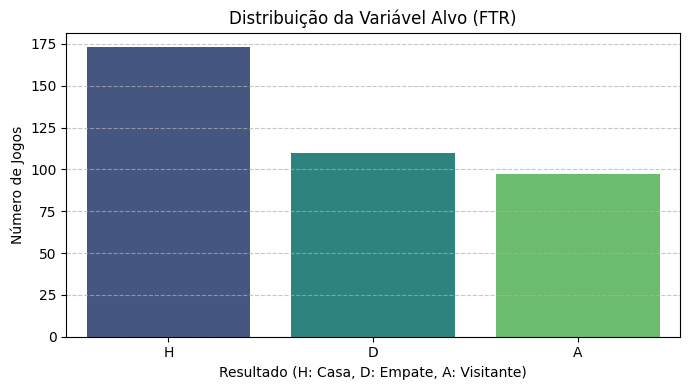



5. MATRIZ DE CORRELAÇÃO


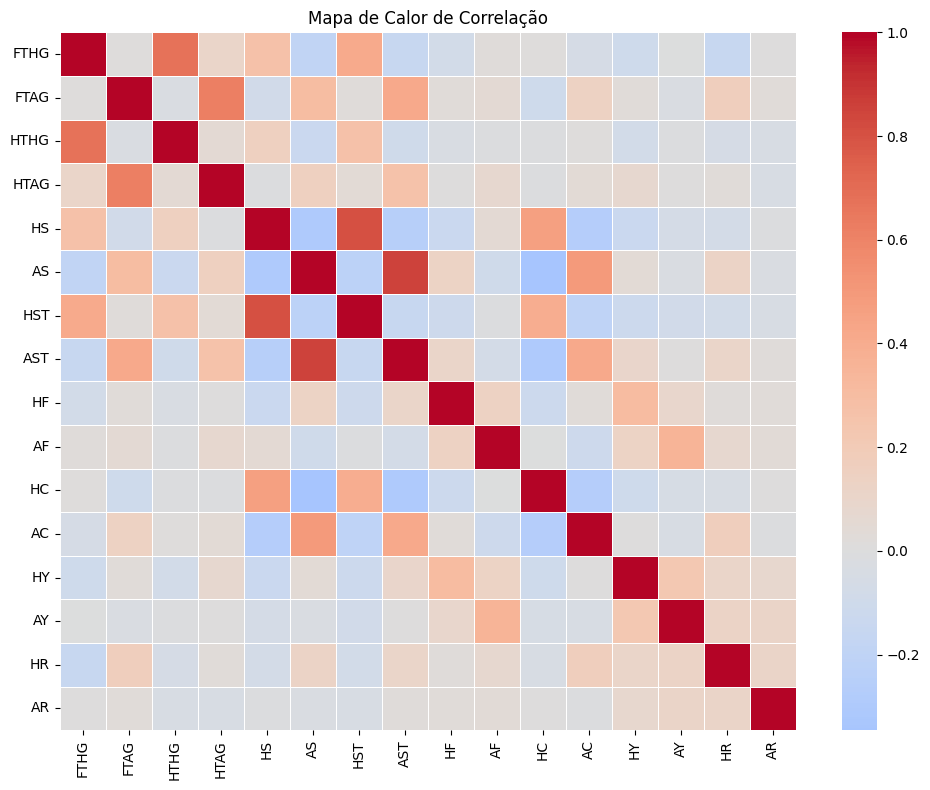




############################################################
 DATASET: 2014-15.csv
############################################################

[INFO] Ficheiro '2014-15.csv' carregado com sucesso!
       Dimensões: 380 linhas e 65 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div      Date    HomeTeam        AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  \
0  E0  16/08/14     Arsenal  Crystal Palace     2     1   H     1     1   D   
1  E0  16/08/14   Leicester         Everton     2     2   D     1     2   A   
2  E0  16/08/14  Man United         Swansea     1     2   A     0     1   A   
3  E0  16/08/14         QPR            Hull     0     1   A     0     0   D   
4  E0  16/08/14       Stoke     Aston Villa     0     1   A     0     0   D   

   ... BbMx>2.5  BbAv>2.5  BbMx<2.5  BbAv<2.5  BbAH  BbAHh  BbMxAHH  BbAvAHH  \
0  ...     1.77      1.72      2.26      2.10    24  -1.50     1.81     1.78   
1  ...     2.10      2.00      1.90      1.80    22   0.25 

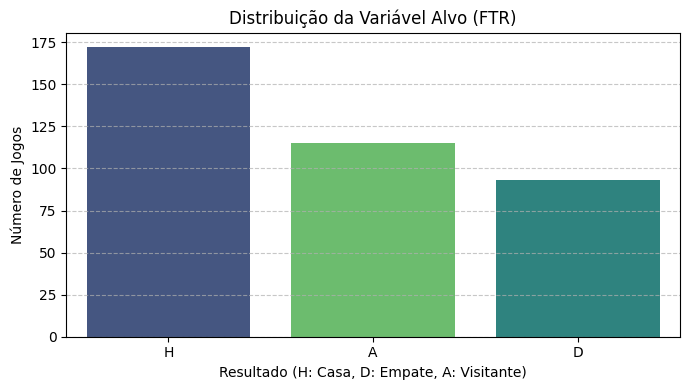



5. MATRIZ DE CORRELAÇÃO


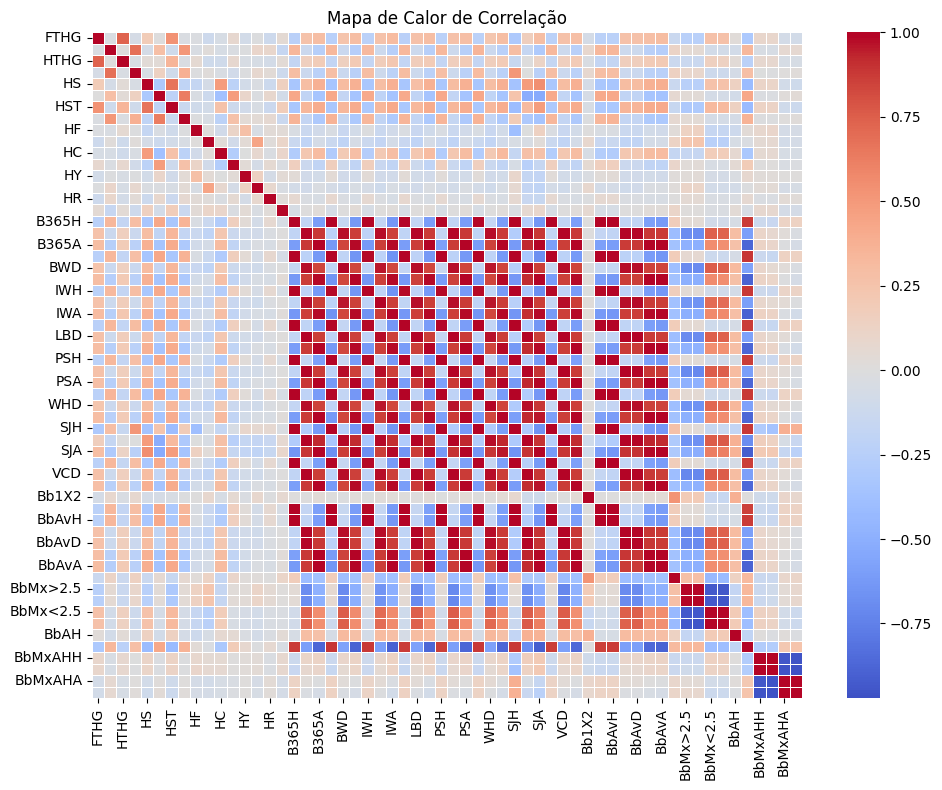




############################################################
 DATASET: 2021-2022.csv
############################################################

[INFO] Ficheiro '2021-2022.csv' carregado com sucesso!
       Dimensões: 380 linhas e 106 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div        Date   Time    HomeTeam        AwayTeam  FTHG  FTAG FTR  HTHG  \
0  E0  13/08/2021  20:00   Brentford         Arsenal     2     0   H     1   
1  E0  14/08/2021  12:30  Man United           Leeds     5     1   H     1   
2  E0  14/08/2021  15:00     Burnley        Brighton     1     2   A     1   
3  E0  14/08/2021  15:00     Chelsea  Crystal Palace     3     0   H     2   
4  E0  14/08/2021  15:00     Everton     Southampton     3     1   H     0   

   HTAG  ... AvgC<2.5  AHCh  B365CAHH  B365CAHA  PCAHH  PCAHA  MaxCAHH  \
0     0  ...     1.62  0.50      1.75      2.05   1.81   2.13     2.05   
1     0  ...     2.25 -1.00      2.05      1.75   2.17   1.77     2.19  

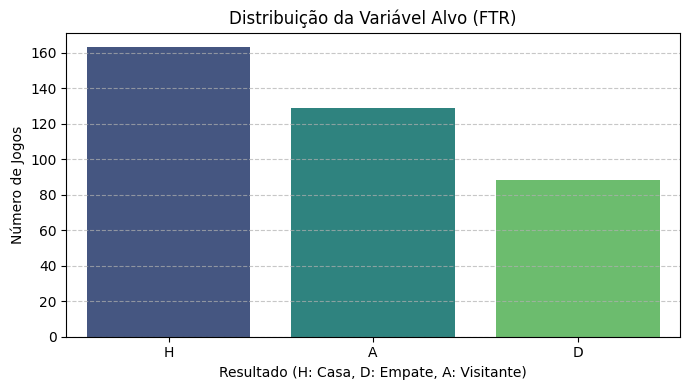



5. MATRIZ DE CORRELAÇÃO


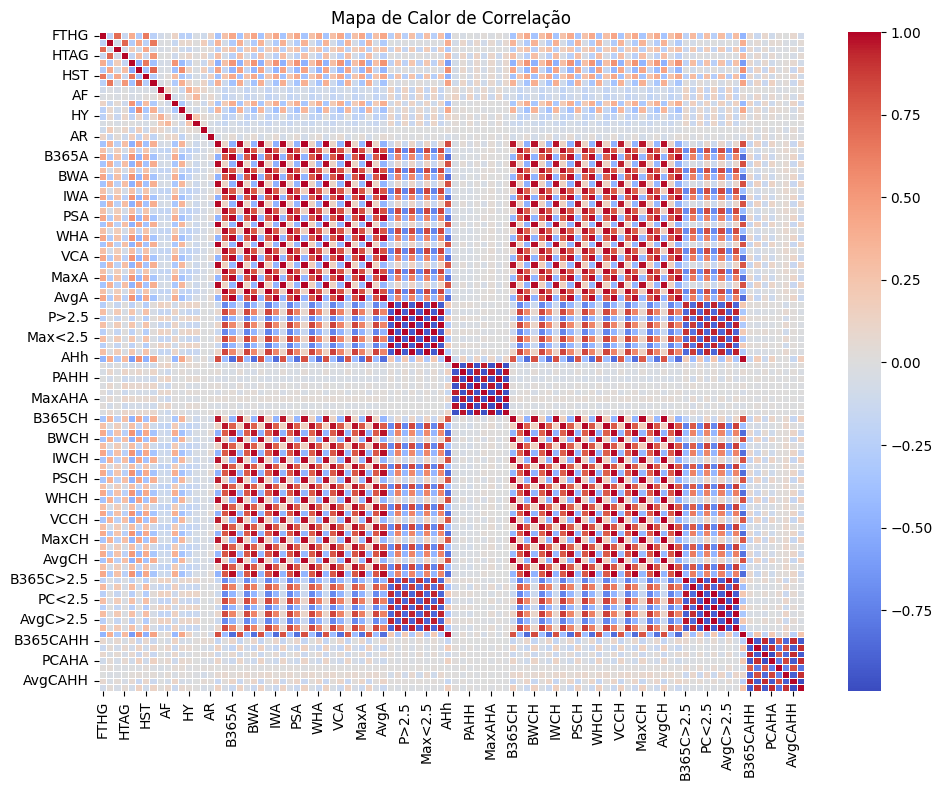




############################################################
 DATASET: 2012-13.csv
############################################################

[INFO] Ficheiro '2012-13.csv' carregado com sucesso!
       Dimensões: 380 linhas e 71 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div      Date   HomeTeam    AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  ...  \
0  E0  18/08/12    Arsenal  Sunderland     0     0   D     0     0   D  ...   
1  E0  18/08/12     Fulham     Norwich     5     0   H     2     0   H  ...   
2  E0  18/08/12  Newcastle   Tottenham     2     1   H     0     0   D  ...   
3  E0  18/08/12        QPR     Swansea     0     5   A     0     1   A  ...   
4  E0  18/08/12    Reading       Stoke     1     1   D     0     1   A  ...   

  BbMx>2.5  BbAv>2.5  BbMx<2.5  BbAv<2.5  BbAH  BbAHh  BbMxAHH  BbAvAHH  \
0     1.83      1.76      2.15      2.05    23  -1.25     2.02     1.96   
1     1.95      1.89      2.01      1.92    21  -0.50     1.83     1.

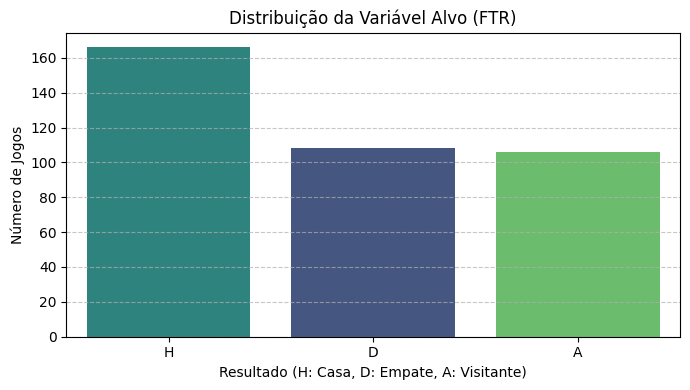



5. MATRIZ DE CORRELAÇÃO


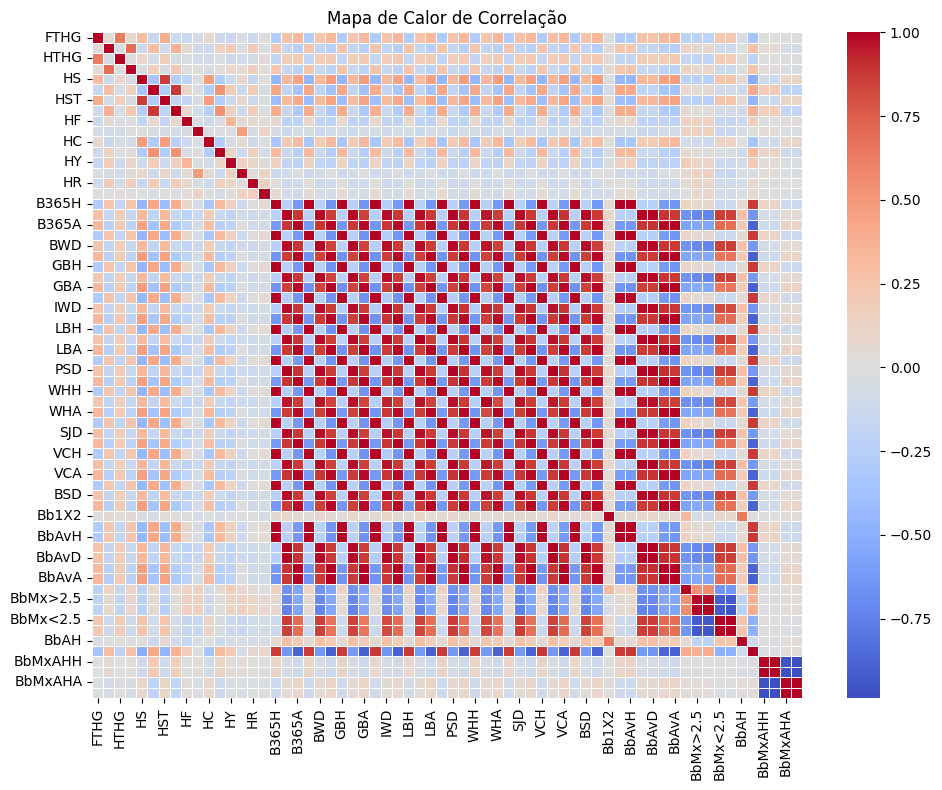




############################################################
 DATASET: 2006-07.csv
############################################################

[INFO] Ficheiro '2006-07.csv' carregado com sucesso!
       Dimensões: 380 linhas e 23 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div      Date    HomeTeam     AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  ...  \
0  E0  19/08/06     Arsenal  Aston Villa     1     1   D     0     0   D  ...   
1  E0  19/08/06      Bolton    Tottenham     2     0   H     2     0   H  ...   
2  E0  19/08/06     Everton      Watford     2     1   H     1     0   H  ...   
3  E0  19/08/06   Newcastle        Wigan     2     1   H     1     0   H  ...   
4  E0  19/08/06  Portsmouth    Blackburn     3     0   H     1     0   H  ...   

  HST  AST  HF  AF  HC  AC  HY  AY  HR  AR  
0  11    3  10  19  18   1   1   2   0   0  
1   6    6  19  22   6   3   0   1   0   0  
2   2    8  12  13   0   6   2   2   0   0  
3   8    9  17  20   4  11 

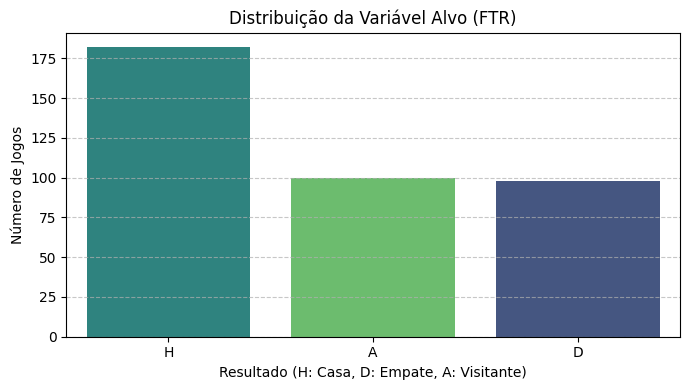



5. MATRIZ DE CORRELAÇÃO


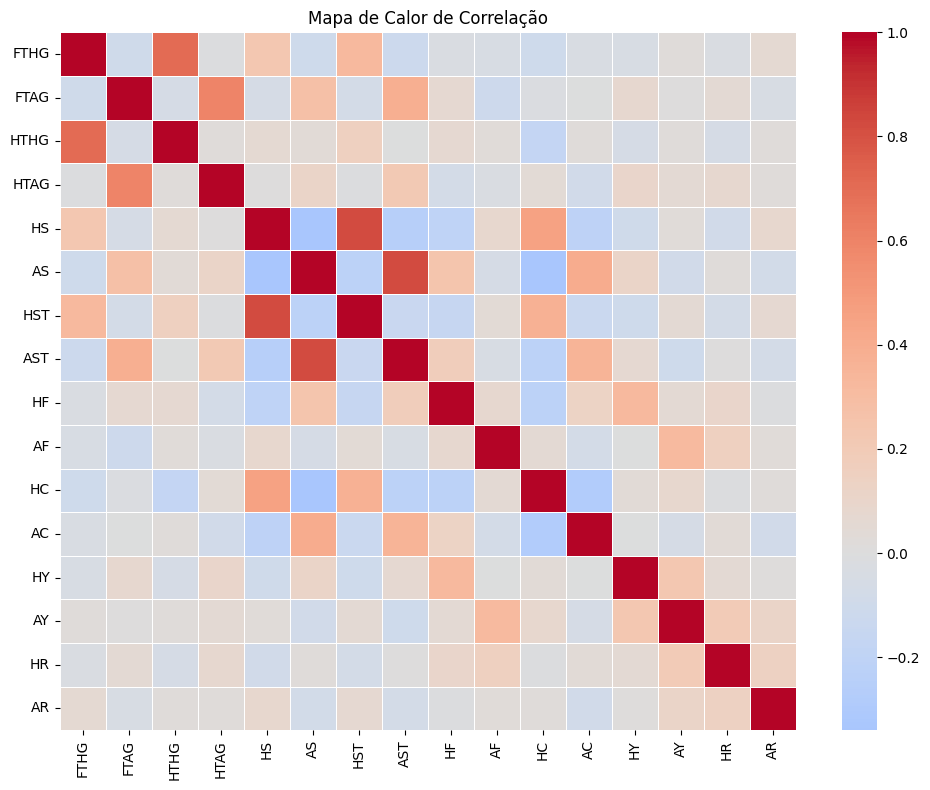




############################################################
 DATASET: 2016-17.csv
############################################################

[INFO] Ficheiro '2016-17.csv' carregado com sucesso!
       Dimensões: 380 linhas e 65 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div      Date        HomeTeam    AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  \
0  E0  13/08/16         Burnley     Swansea     0     1   A     0     0   D   
1  E0  13/08/16  Crystal Palace   West Brom     0     1   A     0     0   D   
2  E0  13/08/16         Everton   Tottenham     1     1   D     1     0   H   
3  E0  13/08/16            Hull   Leicester     2     1   H     1     0   H   
4  E0  13/08/16        Man City  Sunderland     2     1   H     1     0   H   

   ... BbAv<2.5  BbAH  BbAHh  BbMxAHH  BbAvAHH  BbMxAHA  BbAvAHA  PSCH  PSCD  \
0  ...     1.61    32  -0.25     2.13     2.06     1.86     1.81  2.79  3.16   
1  ...     1.52    33  -0.50     2.07     2.00     1.90    

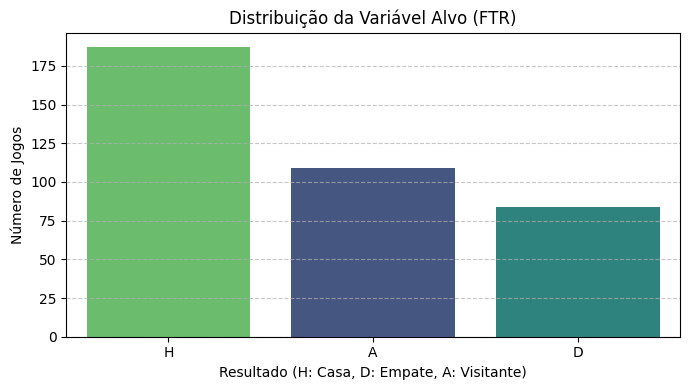



5. MATRIZ DE CORRELAÇÃO


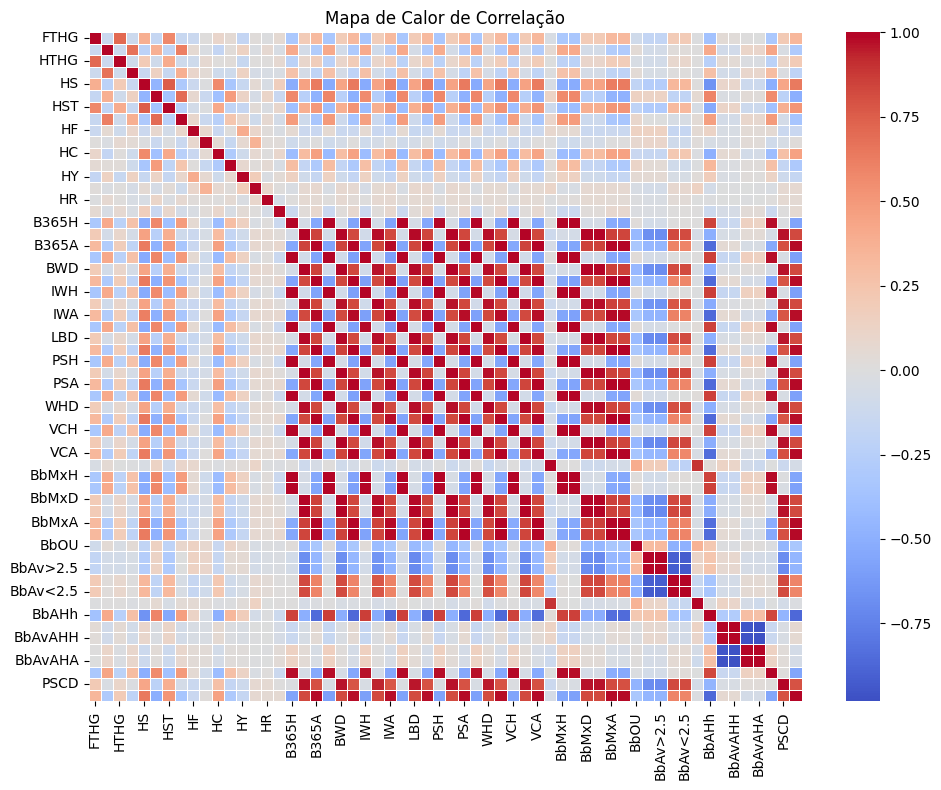




############################################################
 DATASET: 2020-2021.csv
############################################################

[INFO] Ficheiro '2020-2021.csv' carregado com sucesso!
       Dimensões: 380 linhas e 106 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div        Date   Time        HomeTeam     AwayTeam  FTHG  FTAG FTR  HTHG  \
0  E0  12/09/2020  12:30          Fulham      Arsenal     0     3   A     0   
1  E0  12/09/2020  15:00  Crystal Palace  Southampton     1     0   H     1   
2  E0  12/09/2020  17:30       Liverpool        Leeds     4     3   H     3   
3  E0  12/09/2020  20:00        West Ham    Newcastle     0     2   A     0   
4  E0  13/09/2020  14:00       West Brom    Leicester     0     3   A     0   

   HTAG  ... AvgC<2.5  AHCh  B365CAHH  B365CAHA  PCAHH  PCAHA  MaxCAHH  \
0     1  ...     1.84  0.75      2.01      1.89   2.02   1.91     2.13   
1     0  ...     1.70  0.25      1.78      2.13   1.79   2.17     

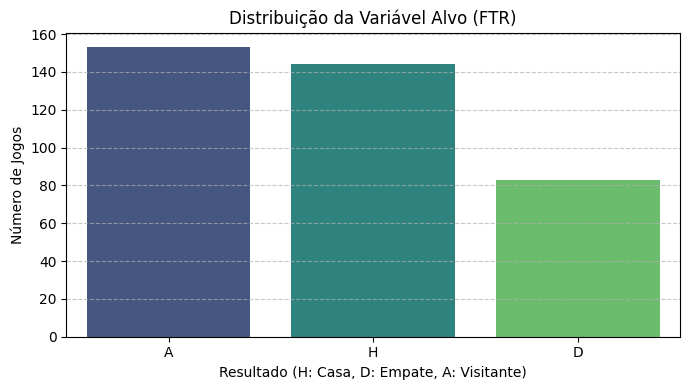



5. MATRIZ DE CORRELAÇÃO


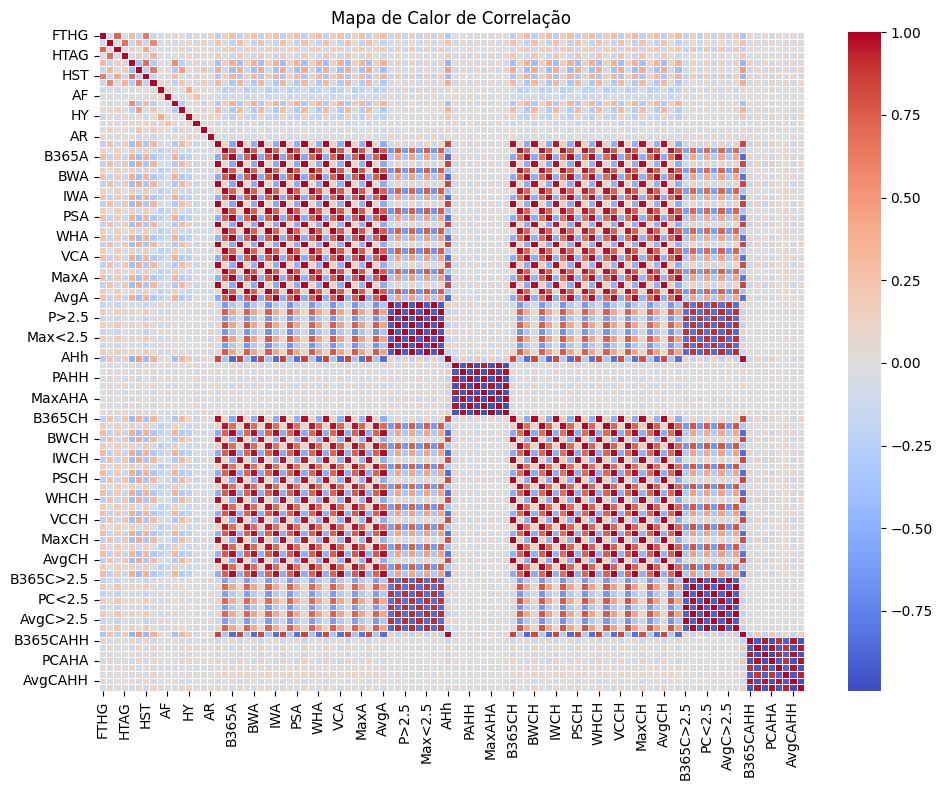




############################################################
 DATASET: 2002-03.csv
############################################################

[INFO] Ficheiro '2002-03.csv' carregado com sucesso!
       Dimensões: 380 linhas e 23 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div        Date   HomeTeam    AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  ...  \
0  E0  17/08/2002  Blackburn  Sunderland     0     0   D     0     0   D  ...   
1  E0  17/08/2002   Charlton     Chelsea     2     3   A     2     1   H  ...   
2  E0  17/08/2002    Everton   Tottenham     2     2   D     1     0   H  ...   
3  E0  17/08/2002     Fulham      Bolton     4     1   H     3     1   H  ...   
4  E0  17/08/2002      Leeds    Man City     3     0   H     2     0   H  ...   

  HST  AST  HF  AF  HC  AC  HY  AY  HR  AR  
0   5    3  14  11   9   1   1   2   0   0  
1   5   12  10  12   3   6   0   3   1   0  
2   9    5  18   4  10   5   1   1   0   0  
3   6    1  16  12   7   4 

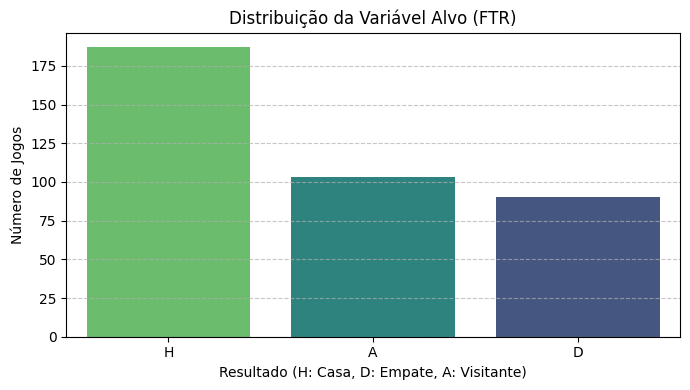



5. MATRIZ DE CORRELAÇÃO


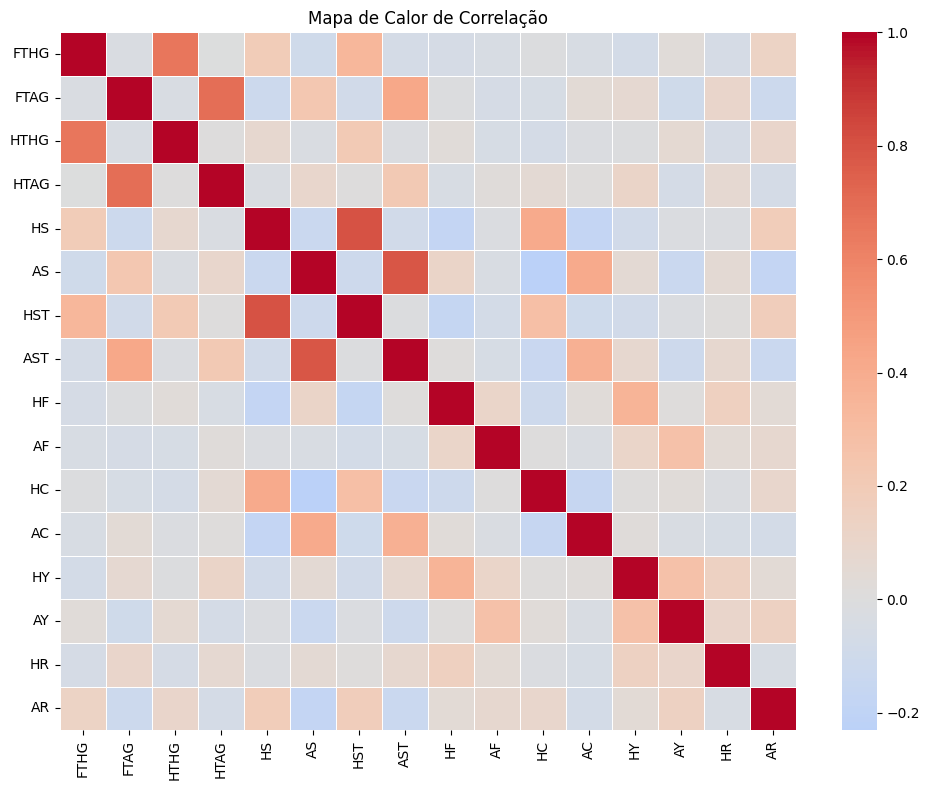




############################################################
 DATASET: EPLStandings.csv
############################################################

[INFO] Ficheiro 'EPLStandings.csv' carregado com sucesso!
       Dimensões: 43 linhas e 18 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
          Team  2000  2001  2002  2003  2004  2005  2006  2007  2008  2009  \
0      Arsenal   2.0   2.0   1.0   2.0   1.0   2.0   4.0   4.0   3.0   4.0   
1  Aston Villa   6.0   8.0   8.0  16.0   6.0  10.0  16.0  11.0   6.0   6.0   
2   Birmingham   NaN   NaN   NaN  13.0  10.0  12.0  18.0   NaN  19.0   NaN   
3    Blackburn   NaN   NaN  10.0   6.0  15.0  15.0   6.0  10.0   7.0  15.0   
4    Blackpool   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   

   2010  2011  2012  2013  2014  2015  2016  
0   3.0   4.0   3.0   4.0   4.0   3.0   2.0  
1   6.0   9.0  16.0  15.0  15.0  17.0  20.0  
2   9.0  18.0   NaN   NaN   NaN   NaN   NaN  
3  10.0  15.0  19.0   NaN   NaN 

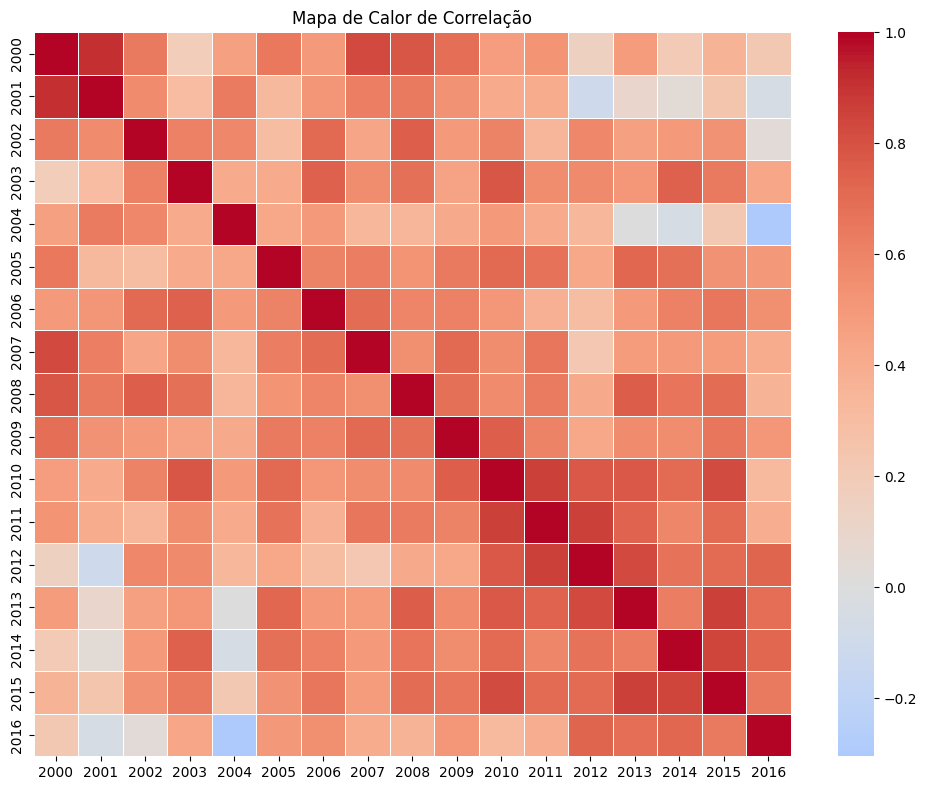




############################################################
 DATASET: 2007-08.csv
############################################################

[INFO] Ficheiro '2007-08.csv' carregado com sucesso!
       Dimensões: 380 linhas e 23 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div      Date       HomeTeam    AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  \
0  E0  11/08/07    Aston Villa   Liverpool     1     2   A     0     1   A   
1  E0  11/08/07         Bolton   Newcastle     1     3   A     0     3   A   
2  E0  11/08/07          Derby  Portsmouth     2     2   D     1     1   D   
3  E0  11/08/07        Everton       Wigan     2     1   H     1     0   H   
4  E0  11/08/07  Middlesbrough   Blackburn     1     2   A     1     0   H   

   ... HST  AST  HF  AF  HC  AC  HY  AY  HR  AR  
0  ...   6    7  18  11   4   2   4   2   0   0  
1  ...   9    5  15  16   4   3   1   1   0   0  
2  ...   5    6  14  17   6   6   1   2   0   0  
3  ...   8    4   8  13  

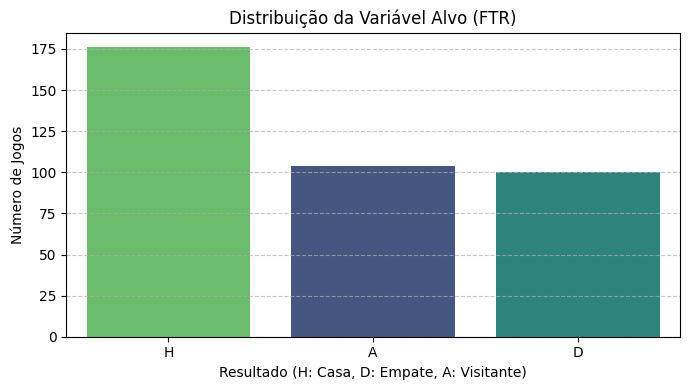



5. MATRIZ DE CORRELAÇÃO


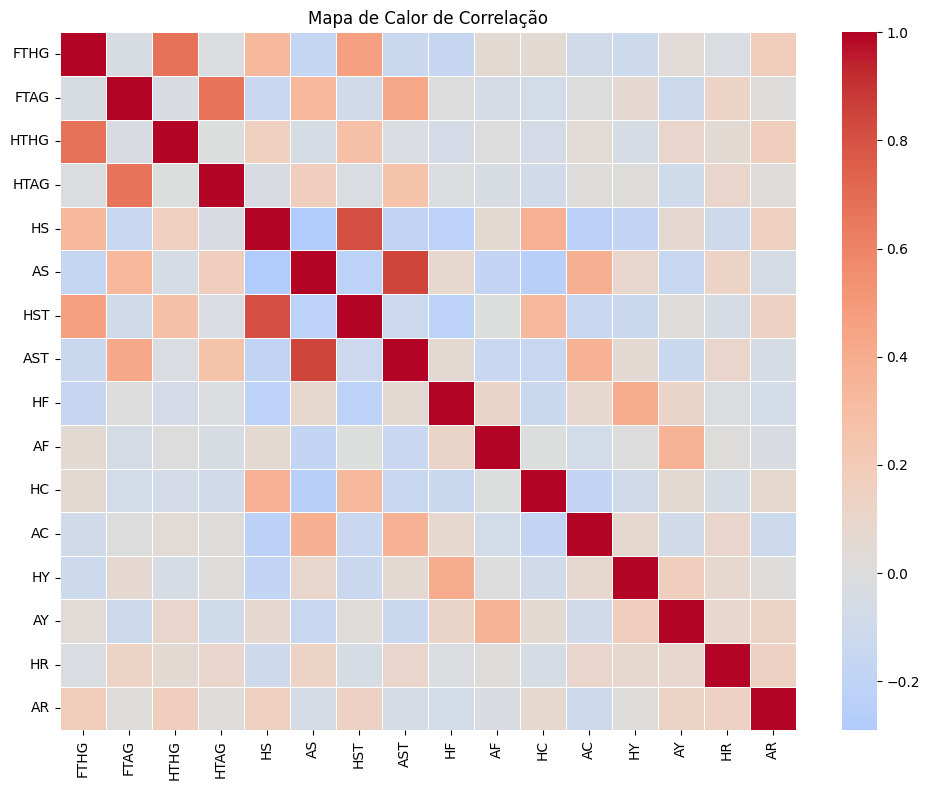




############################################################
 DATASET: 2011-12.csv
############################################################

[INFO] Ficheiro '2011-12.csv' carregado com sucesso!
       Dimensões: 380 linhas e 71 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div      Date   HomeTeam     AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  ...  \
0  E0  13/08/11  Blackburn       Wolves     1     2   A     1     1   D  ...   
1  E0  13/08/11     Fulham  Aston Villa     0     0   D     0     0   D  ...   
2  E0  13/08/11  Liverpool   Sunderland     1     1   D     1     0   H  ...   
3  E0  13/08/11  Newcastle      Arsenal     0     0   D     0     0   D  ...   
4  E0  13/08/11        QPR       Bolton     0     4   A     0     1   A  ...   

  BbMx>2.5  BbAv>2.5  BbMx<2.5  BbAv<2.5  BbAH  BbAHh  BbMxAHH  BbAvAHH  \
0     2.06      1.96      1.89      1.82    18  -0.50     2.20     2.14   
1     2.21      2.11      1.77      1.69    21  -0.25     1.83 

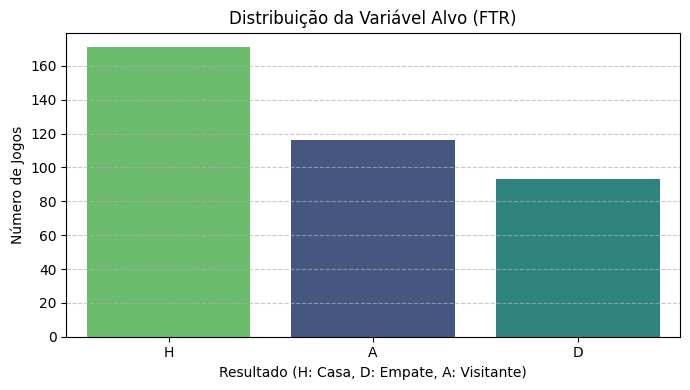



5. MATRIZ DE CORRELAÇÃO


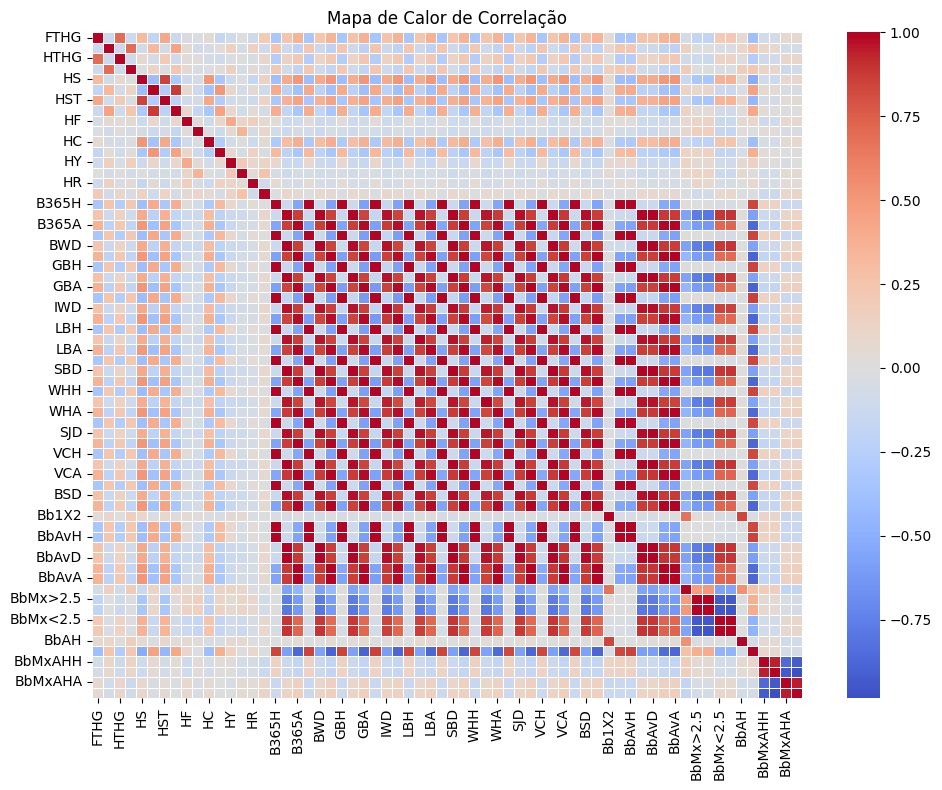




############################################################
 DATASET: 2008-09.csv
############################################################

[INFO] Ficheiro '2008-09.csv' carregado com sucesso!
       Dimensões: 380 linhas e 23 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div      Date       HomeTeam   AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  \
0  E0  16/08/08        Arsenal  West Brom     1     0   H     1     0   H   
1  E0  16/08/08         Bolton      Stoke     3     1   H     3     0   H   
2  E0  16/08/08        Everton  Blackburn     2     3   A     1     1   D   
3  E0  16/08/08           Hull     Fulham     2     1   H     1     1   D   
4  E0  16/08/08  Middlesbrough  Tottenham     2     1   H     0     0   D   

   ... HST  AST  HF  AF  HC  AC  HY  AY  HR  AR  
0  ...  14    4  11   8   7   5   0   0   0   0  
1  ...   8    2  13  12   4   3   1   2   0   0  
2  ...   5   11  11   9   3   5   2   2   0   0  
3  ...   6    6  10   9   5   6

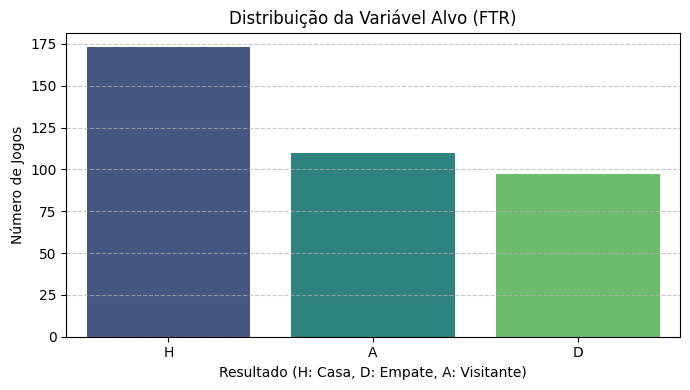



5. MATRIZ DE CORRELAÇÃO


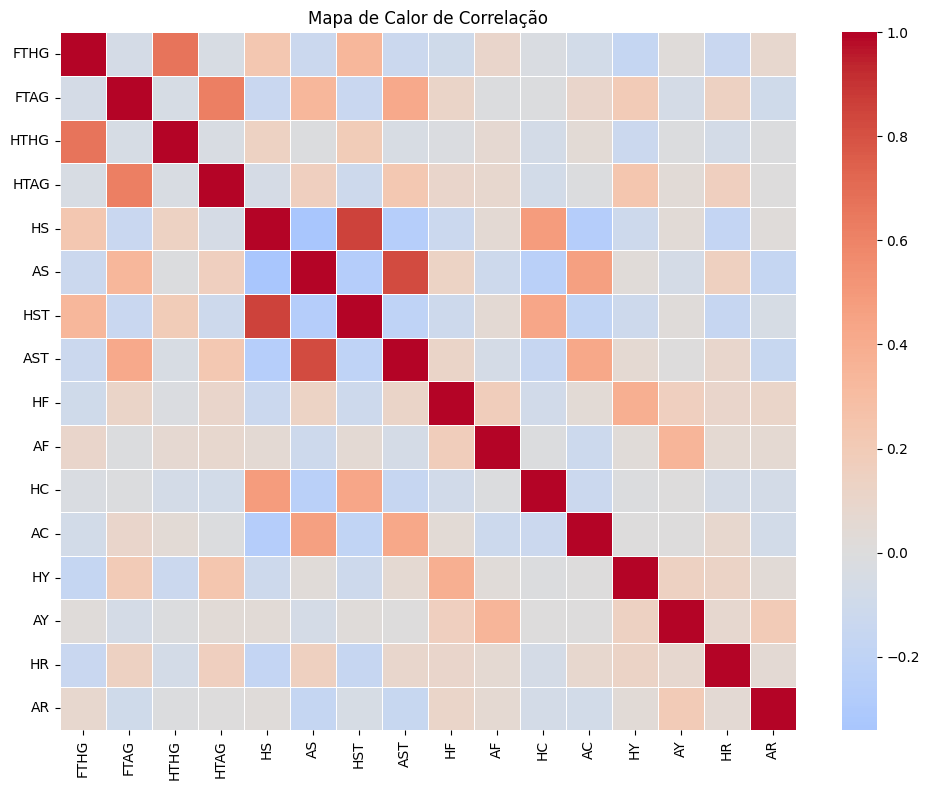




############################################################
 DATASET: 2003-04.csv
############################################################

[INFO] Ficheiro '2003-04.csv' carregado com sucesso!
       Dimensões: 380 linhas e 23 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div      Date    HomeTeam       AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  \
0  E0  16/08/03     Arsenal        Everton     2     1   H     1     0   H   
1  E0  16/08/03  Birmingham      Tottenham     1     0   H     1     0   H   
2  E0  16/08/03   Blackburn         Wolves     5     1   H     2     0   H   
3  E0  16/08/03      Fulham  Middlesbrough     3     2   H     1     1   D   
4  E0  16/08/03   Leicester    Southampton     2     2   D     2     0   H   

   ... HST  AST  HF  AF  HC  AC  HY  AY  HR  AR  
0  ...   5    7   8  15   6   9   1   3   1   1  
1  ...   5    7  20  27   1   4   3   5   0   0  
2  ...  13    5   8  14   6   2   1   1   0   0  
3  ...   9    5  18  16  

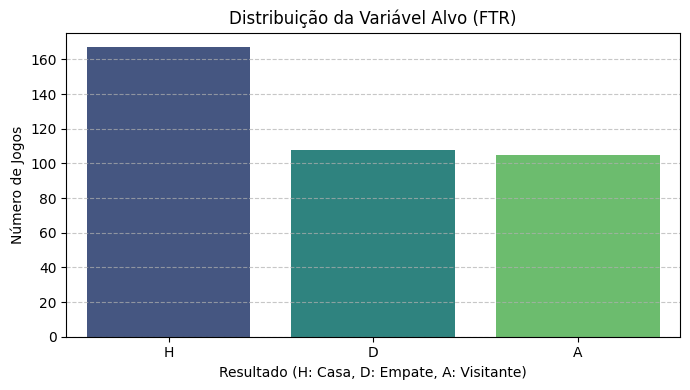



5. MATRIZ DE CORRELAÇÃO


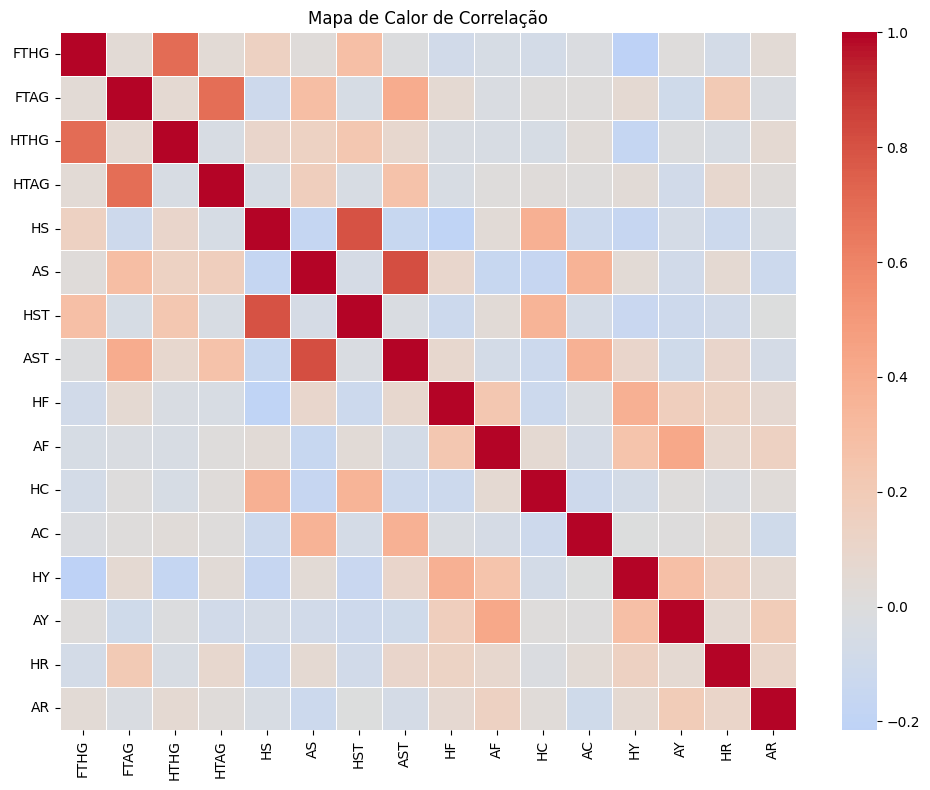




############################################################
 DATASET: 2005-06.csv
############################################################

[INFO] Ficheiro '2005-06.csv' carregado com sucesso!
       Dimensões: 380 linhas e 23 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div      Date       HomeTeam    AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  \
0  E0  13/08/05    Aston Villa      Bolton     2     2   D     2     2   D   
1  E0  13/08/05        Everton  Man United     0     2   A     0     1   A   
2  E0  13/08/05         Fulham  Birmingham     0     0   D     0     0   D   
3  E0  13/08/05       Man City   West Brom     0     0   D     0     0   D   
4  E0  13/08/05  Middlesbrough   Liverpool     0     0   D     0     0   D   

   ... HST  AST  HF  AF  HC  AC  HY  AY  HR  AR  
0  ...   2    6  14  16   7   8   0   2   0   0  
1  ...   5    5  15  14   8   6   3   1   0   0  
2  ...   7    4  12  13   6   6   1   2   0   0  
3  ...   8    3  13  11  

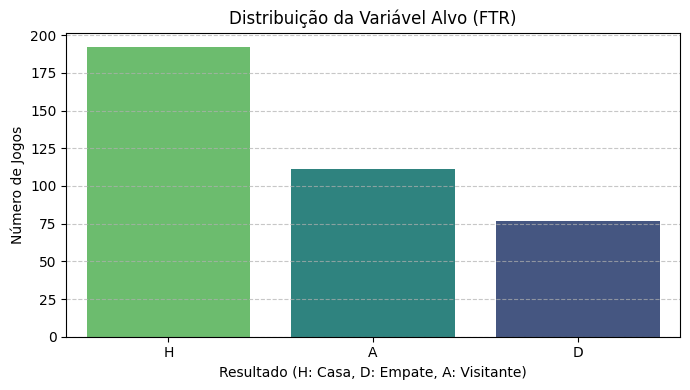



5. MATRIZ DE CORRELAÇÃO


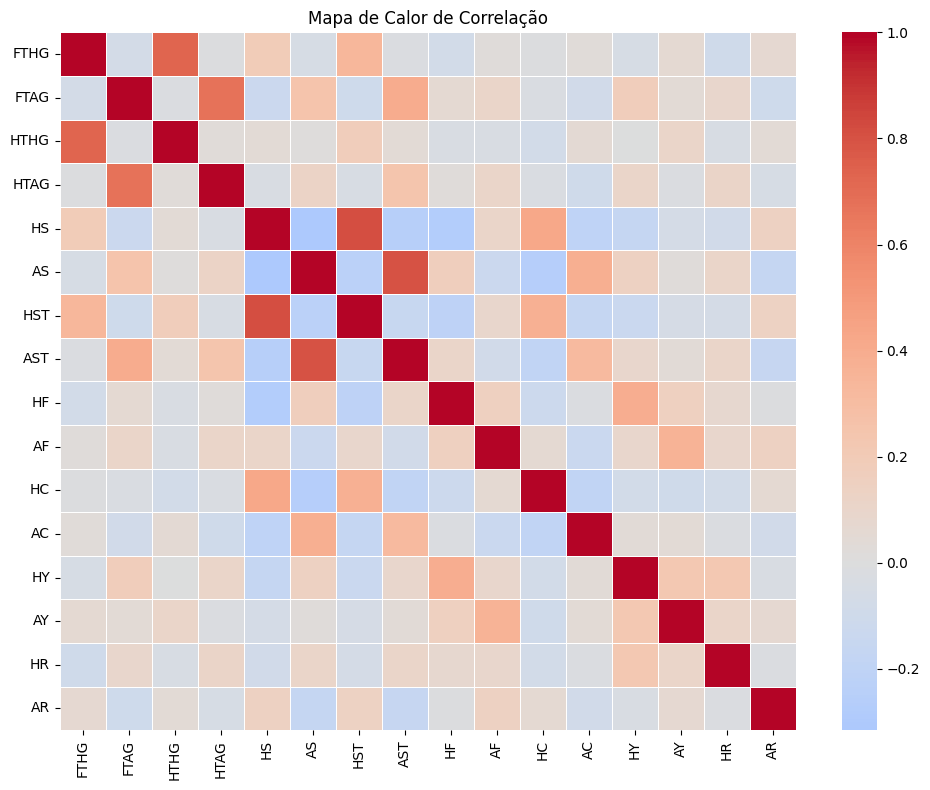




############################################################
 DATASET: 2009-10.csv
############################################################

[INFO] Ficheiro '2009-10.csv' carregado com sucesso!
       Dimensões: 380 linhas e 71 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div      Date     HomeTeam    AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  ...  \
0  E0  15/08/09  Aston Villa       Wigan     0     2   A     0     1   A  ...   
1  E0  15/08/09    Blackburn    Man City     0     2   A     0     1   A  ...   
2  E0  15/08/09       Bolton  Sunderland     0     1   A     0     1   A  ...   
3  E0  15/08/09      Chelsea        Hull     2     1   H     1     1   D  ...   
4  E0  15/08/09      Everton     Arsenal     1     6   A     0     3   A  ...   

  BbMx>2.5  BbAv>2.5  BbMx<2.5  BbAv<2.5  BbAH  BbAHh  BbMxAHH  BbAvAHH  \
0     2.04      1.92      1.91      1.81    21    0.0     1.28     1.22   
1     2.15      2.04      1.78      1.71    24    0.0    

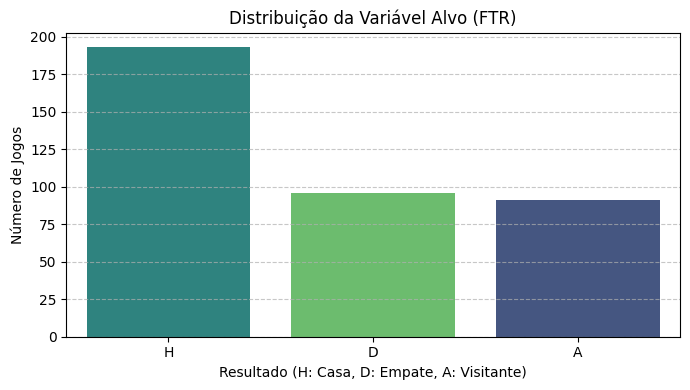



5. MATRIZ DE CORRELAÇÃO


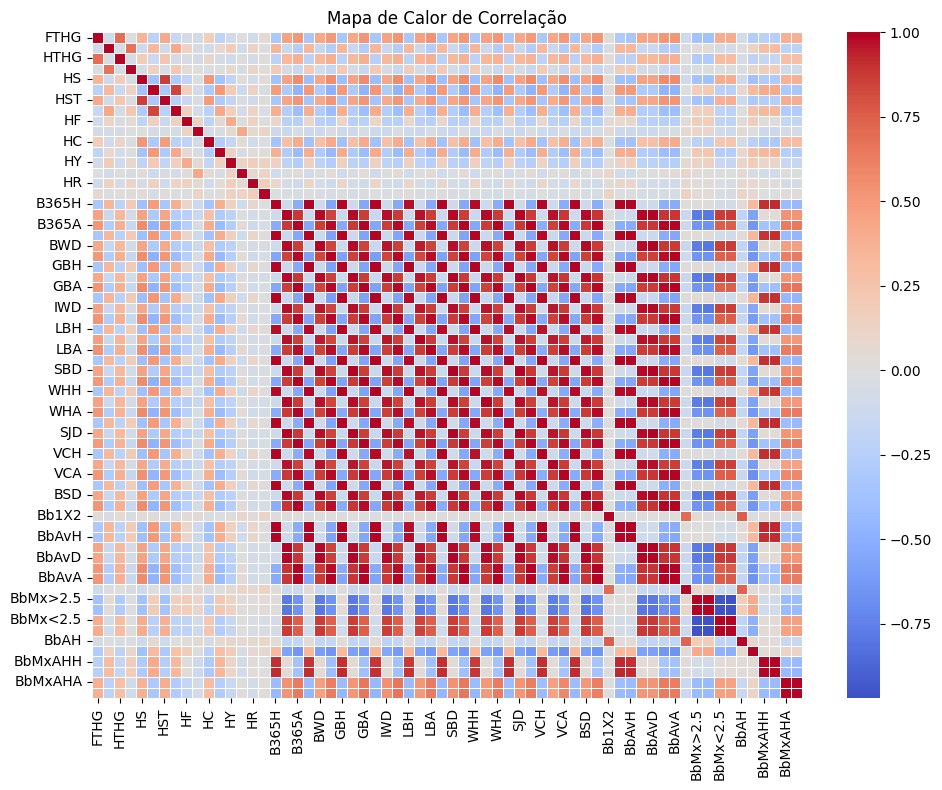




############################################################
 DATASET: 2000-01.csv
############################################################

[INFO] Ficheiro '2000-01.csv' carregado com sucesso!
       Dimensões: 380 linhas e 28 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div      Date  HomeTeam       AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  ...  \
0  E0  19/08/00  Charlton       Man City     4     0   H     2     0   H  ...   
1  E0  19/08/00   Chelsea       West Ham     4     2   H     1     0   H  ...   
2  E0  19/08/00  Coventry  Middlesbrough     1     3   A     1     1   D  ...   
3  E0  19/08/00     Derby    Southampton     2     2   D     1     2   A  ...   
4  E0  19/08/00     Leeds        Everton     2     0   H     2     0   H  ...   

   HC AC  HF  AF  HO  AO  HY  AY  HR  AR  
0   6  6  13  12   8   6   1   2   0   0  
1   7  7  19  14   2   3   1   2   0   0  
2   8  4  15  21   1   3   5   3   1   0  
3   5  8  11  13   0   2   1   1   

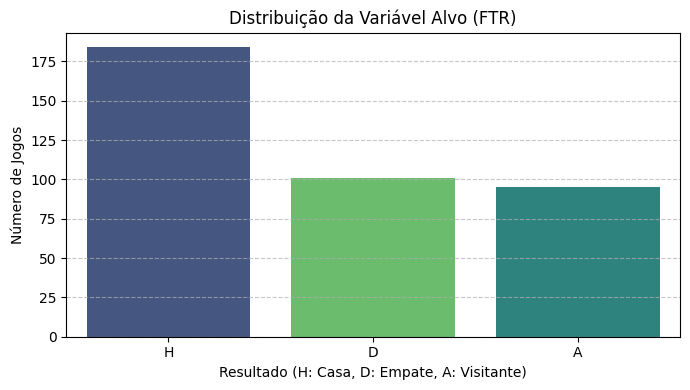



5. MATRIZ DE CORRELAÇÃO


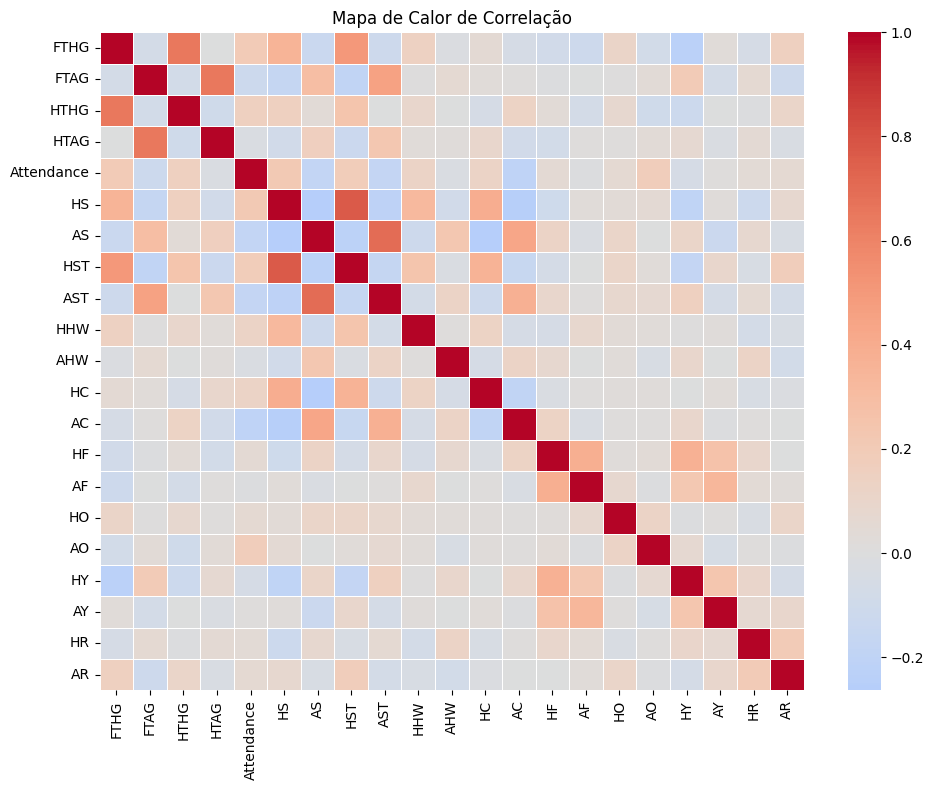




############################################################
 DATASET: 2013-14.csv
############################################################

[INFO] Ficheiro '2013-14.csv' carregado com sucesso!
       Dimensões: 380 linhas e 65 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div      Date    HomeTeam     AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  ...  \
0  E0  17/08/13     Arsenal  Aston Villa     1     3   A     1     1   D  ...   
1  E0  17/08/13   Liverpool        Stoke     1     0   H     1     0   H  ...   
2  E0  17/08/13     Norwich      Everton     2     2   D     0     0   D  ...   
3  E0  17/08/13  Sunderland       Fulham     0     1   A     0     0   D  ...   
4  E0  17/08/13     Swansea   Man United     1     4   A     0     2   A  ...   

  BbMx>2.5  BbAv>2.5  BbMx<2.5  BbAv<2.5  BbAH  BbAHh  BbMxAHH  BbAvAHH  \
0     1.62      1.56      2.56      2.37   NaN    NaN      NaN      NaN   
1     1.86      1.79      2.12      2.02   NaN    NaN    

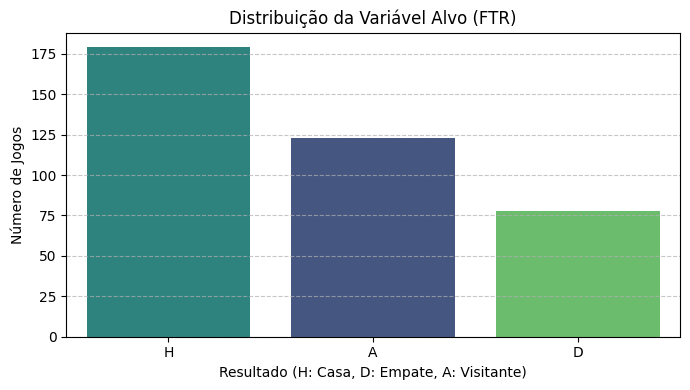



5. MATRIZ DE CORRELAÇÃO


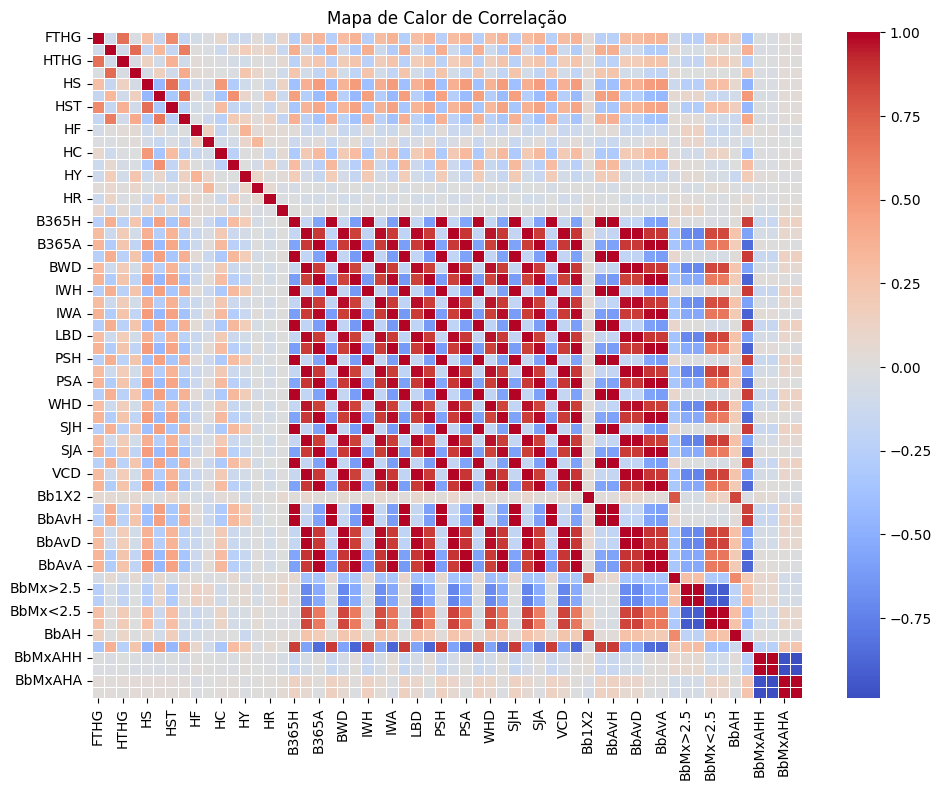




############################################################
 DATASET: 2015-16.csv
############################################################

[INFO] Ficheiro '2015-16.csv' carregado com sucesso!
       Dimensões: 380 linhas e 62 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div      Date     HomeTeam     AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  \
0  E0  08/08/15  Bournemouth  Aston Villa     0     1   A     0     0   D   
1  E0  08/08/15      Chelsea      Swansea     2     2   D     2     1   H   
2  E0  08/08/15      Everton      Watford     2     2   D     0     1   A   
3  E0  08/08/15    Leicester   Sunderland     4     2   H     3     0   H   
4  E0  08/08/15   Man United    Tottenham     1     0   H     1     0   H   

   ... BbMx>2.5  BbAv>2.5  BbMx<2.5  BbAv<2.5  BbAH  BbAHh  BbMxAHH  BbAvAHH  \
0  ...     2.11      2.02      1.88      1.79    26   -0.5     1.98     1.93   
1  ...     1.88      1.80      2.07      1.99    27   -1.5     2.24    

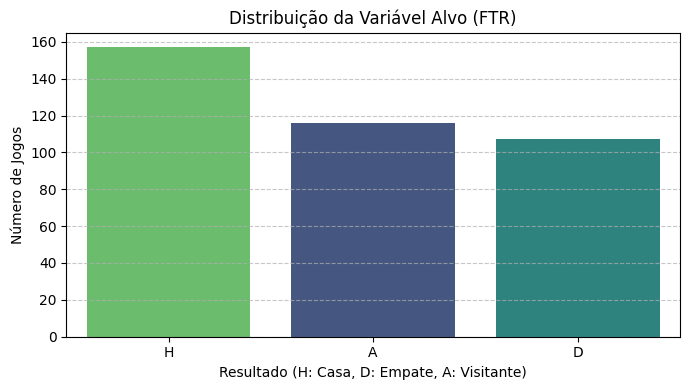



5. MATRIZ DE CORRELAÇÃO


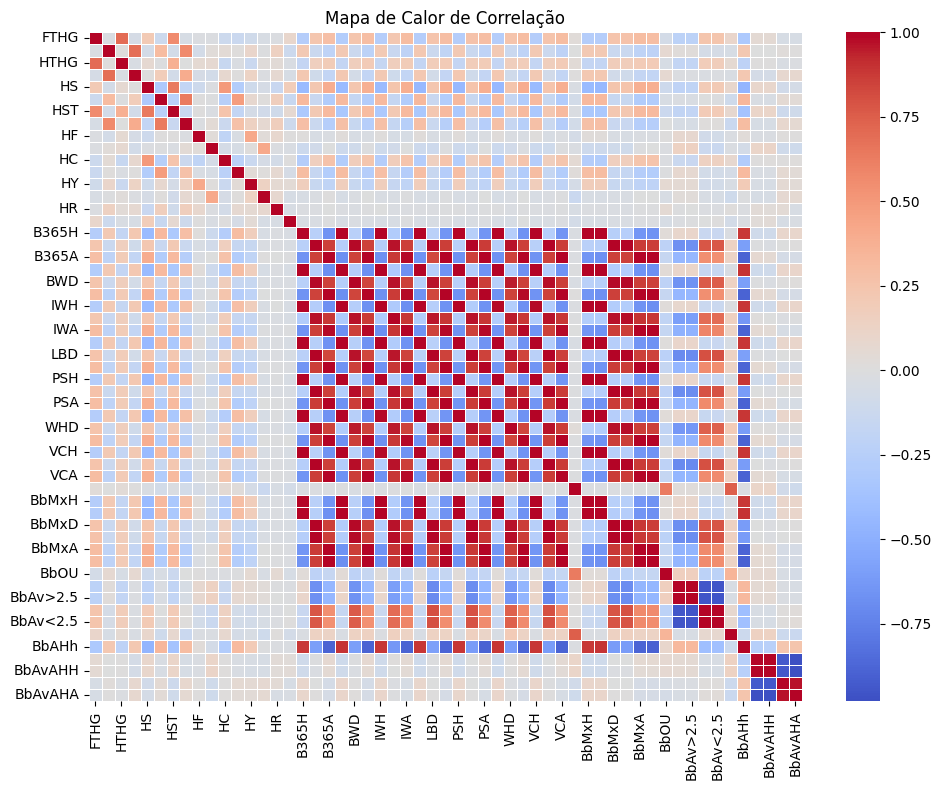




############################################################
 DATASET: 2001-02.csv
############################################################

[INFO] Ficheiro '2001-02.csv' carregado com sucesso!
       Dimensões: 380 linhas e 28 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div      Date   HomeTeam     AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  ...  \
0  E0  18/08/01   Charlton      Everton     1     2   A     0     0   D  ...   
1  E0  18/08/01      Derby    Blackburn     2     1   H     1     0   H  ...   
2  E0  18/08/01      Leeds  Southampton     2     0   H     0     0   D  ...   
3  E0  18/08/01  Leicester       Bolton     0     5   A     0     4   A  ...   
4  E0  18/08/01  Liverpool     West Ham     2     1   H     1     1   D  ...   

   HC  AC  HF  AF  HO  AO  HY  AY  HR  AR  
0   4   4  15  17   2   1   0   3   0   0  
1   4  10  14  15   3   1   1   0   0   0  
2  10   3  16  24   3   2   1   2   0   1  
3   3   5  21  17   4   0   4   3   0

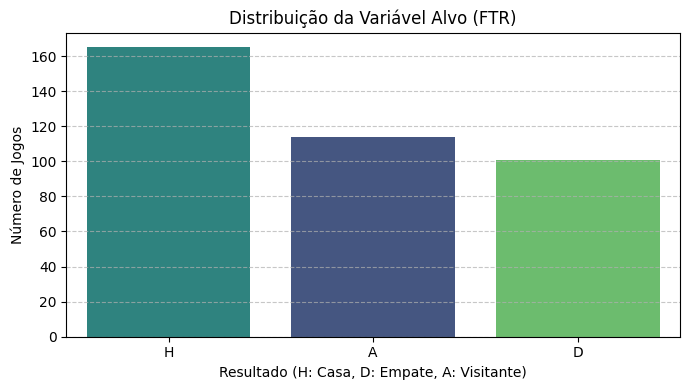



5. MATRIZ DE CORRELAÇÃO


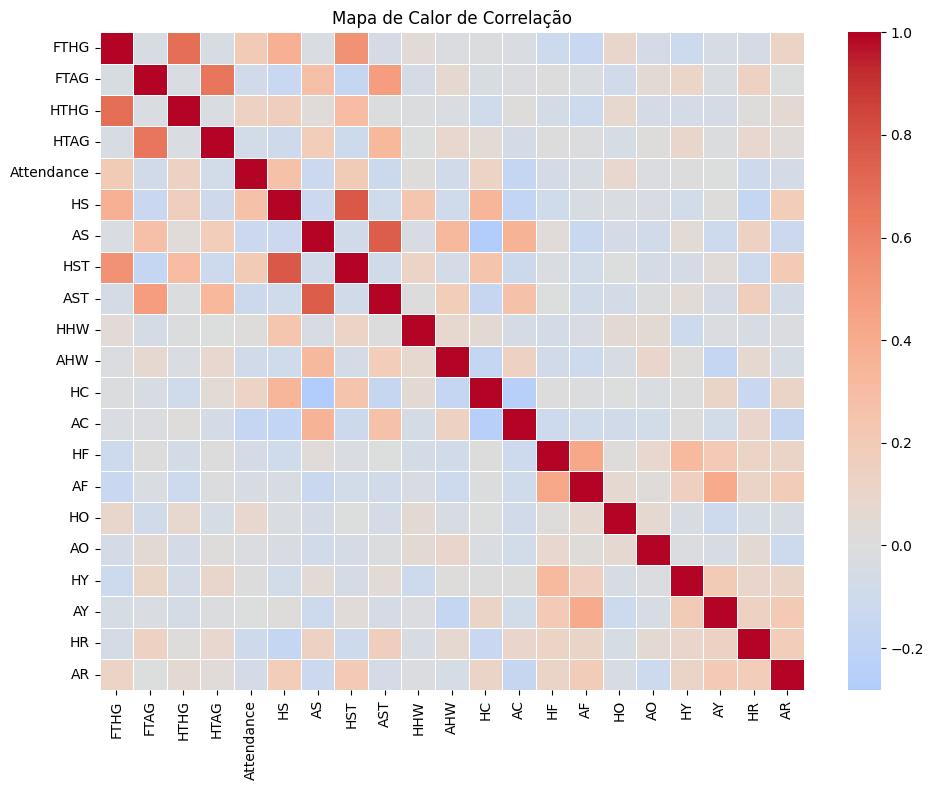




############################################################
 DATASET: 2019-20.csv
############################################################

[INFO] Ficheiro '2019-20.csv' carregado com sucesso!
       Dimensões: 260 linhas e 106 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div        Date   Time        HomeTeam          AwayTeam  FTHG  FTAG FTR  \
0  E0  09/08/2019  20:00       Liverpool           Norwich     4     1   H   
1  E0  10/08/2019  12:30        West Ham          Man City     0     5   A   
2  E0  10/08/2019  15:00     Bournemouth  Sheffield United     1     1   D   
3  E0  10/08/2019  15:00         Burnley       Southampton     3     0   H   
4  E0  10/08/2019  15:00  Crystal Palace           Everton     0     0   D   

   HTHG  HTAG  ... AvgC<2.5  AHCh  B365CAHH  B365CAHA  PCAHH  PCAHA  MaxCAHH  \
0     4     0  ...     3.43 -2.25      1.91      1.99   1.94   1.98     1.99   
1     0     1  ...     2.91  1.75      1.95      1.95   1.96   1

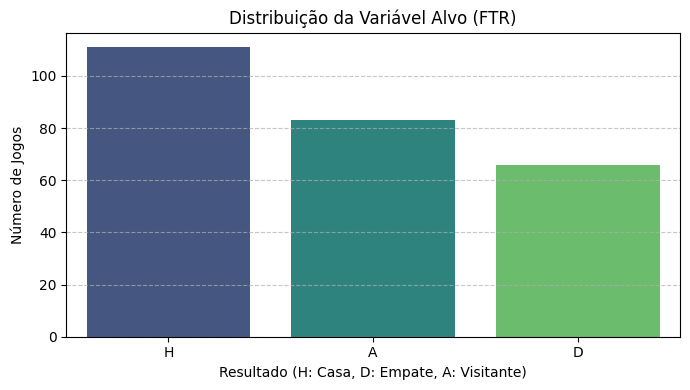



5. MATRIZ DE CORRELAÇÃO


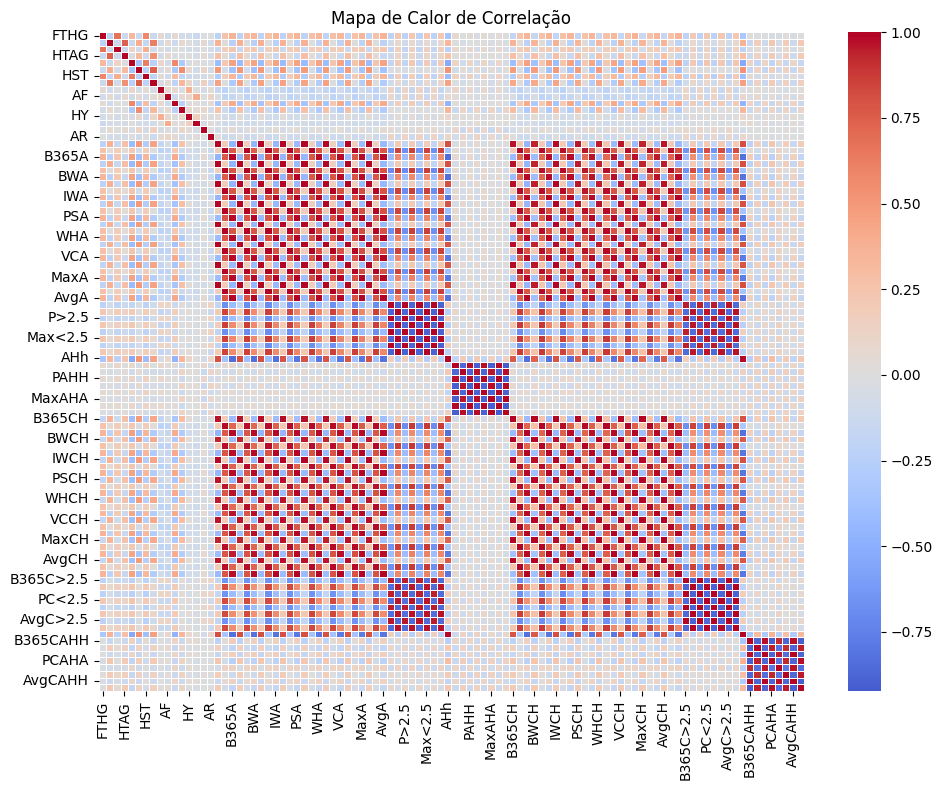




############################################################
 DATASET: 2018-19.csv
############################################################

[INFO] Ficheiro '2018-19.csv' carregado com sucesso!
       Dimensões: 160 linhas e 62 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div      Date      HomeTeam        AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  \
0  E0  10/08/18    Man United       Leicester     2     1   H     1     0   H   
1  E0  11/08/18   Bournemouth         Cardiff     2     0   H     1     0   H   
2  E0  11/08/18        Fulham  Crystal Palace     0     2   A     0     1   A   
3  E0  11/08/18  Huddersfield         Chelsea     0     3   A     0     2   A   
4  E0  11/08/18     Newcastle       Tottenham     1     2   A     1     2   A   

   ... BbAv<2.5  BbAH  BbAHh  BbMxAHH  BbAvAHH  BbMxAHA  BbAvAHA  PSCH  PSCD  \
0  ...     1.79    17  -0.75     1.75     1.70     2.29     2.21  1.55  4.07   
1  ...     1.83    20  -0.75     2.20     2.13 

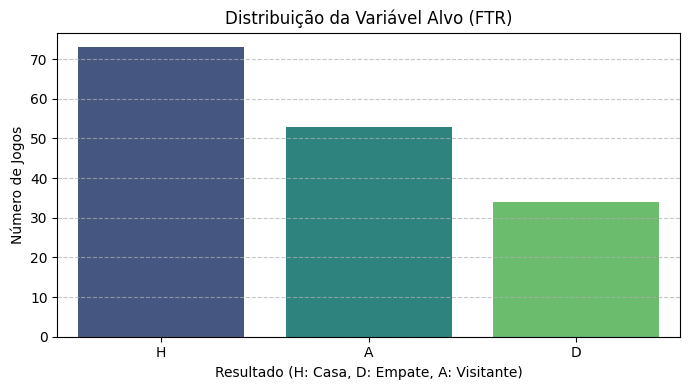



5. MATRIZ DE CORRELAÇÃO


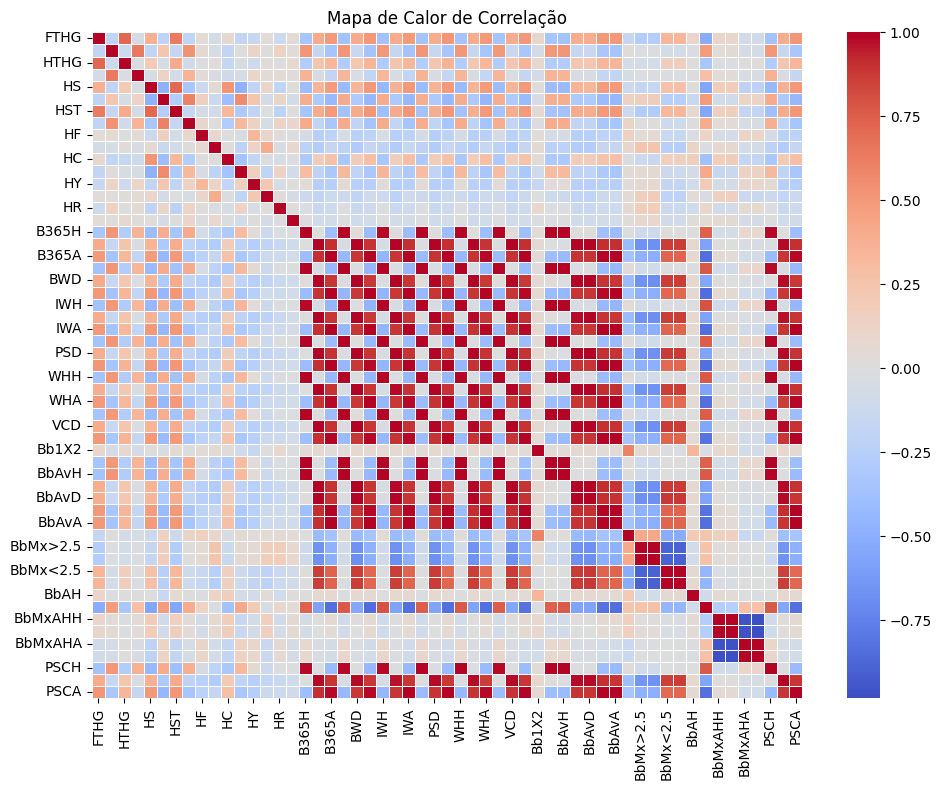




############################################################
 DATASET: 2017-18.csv
############################################################

[INFO] Ficheiro '2017-18.csv' carregado com sucesso!
       Dimensões: 380 linhas e 65 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div      Date        HomeTeam      AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  \
0  E0  11/08/17         Arsenal     Leicester     4     3   H     2     2   D   
1  E0  12/08/17        Brighton      Man City     0     2   A     0     0   D   
2  E0  12/08/17         Chelsea       Burnley     2     3   A     0     3   A   
3  E0  12/08/17  Crystal Palace  Huddersfield     0     3   A     0     2   A   
4  E0  12/08/17         Everton         Stoke     1     0   H     1     0   H   

   ... BbAv<2.5  BbAH  BbAHh  BbMxAHH  BbAvAHH  BbMxAHA  BbAvAHA   PSCH  PSCD  \
0  ...     2.32    21  -1.00     1.91     1.85     2.10     2.02   1.49  4.73   
1  ...     2.27    20   1.50     1.95     1.9

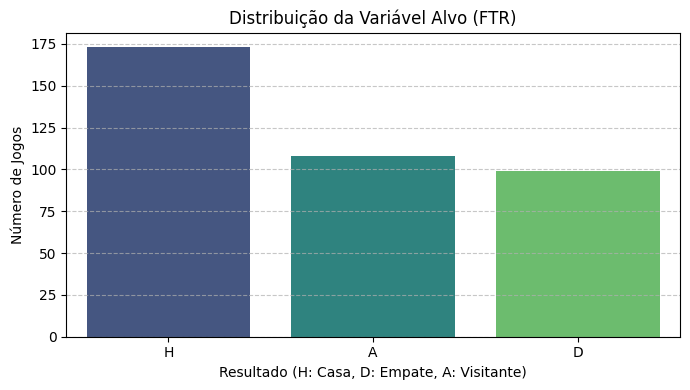



5. MATRIZ DE CORRELAÇÃO


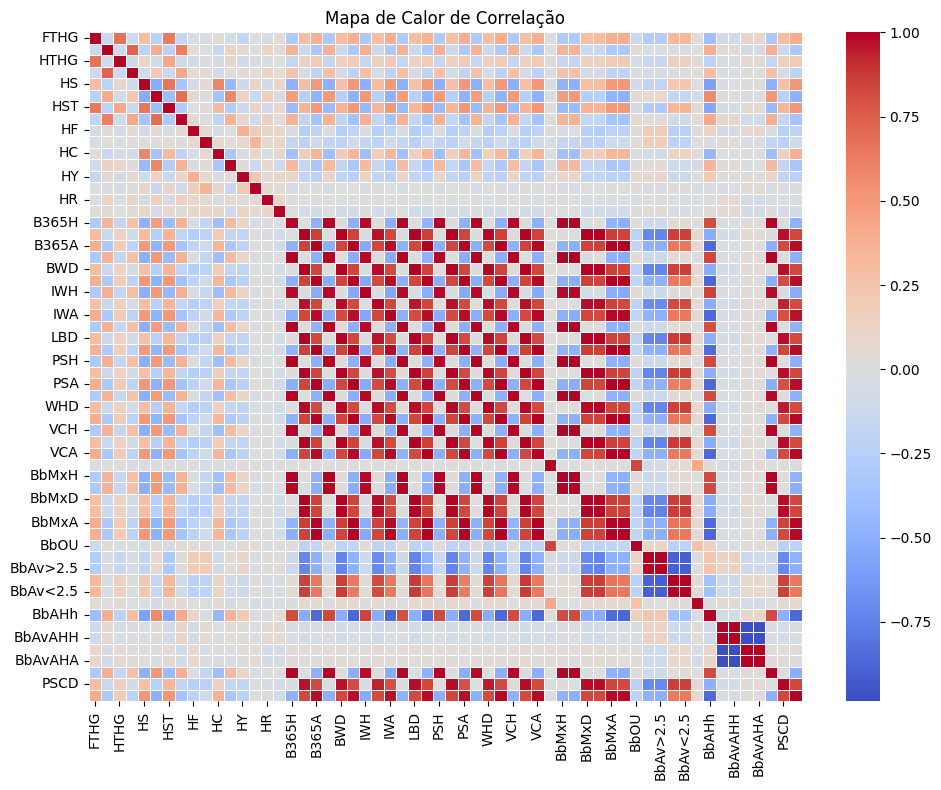




############################################################
 DATASET: 2010-11.csv
############################################################

[INFO] Ficheiro '2010-11.csv' carregado com sucesso!
       Dimensões: 380 linhas e 71 colunas.

1. RESUMO DA ESTRUTURA DOS DADOS

--- Primeiras 5 linhas ---
  Div      Date     HomeTeam    AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  ...  \
0  E0  14/08/10  Aston Villa    West Ham     3     0   H     2     0   H  ...   
1  E0  14/08/10    Blackburn     Everton     1     0   H     1     0   H  ...   
2  E0  14/08/10       Bolton      Fulham     0     0   D     0     0   D  ...   
3  E0  14/08/10      Chelsea   West Brom     6     0   H     2     0   H  ...   
4  E0  14/08/10   Sunderland  Birmingham     2     2   D     1     0   H  ...   

  BbMx>2.5  BbAv>2.5  BbMx<2.5  BbAv<2.5  BbAH  BbAHh  BbMxAHH  BbAvAHH  \
0     2.11      2.01      1.82      1.75    20    0.0     1.45     1.40   
1     2.20      2.08      1.79      1.70    29    0.0    

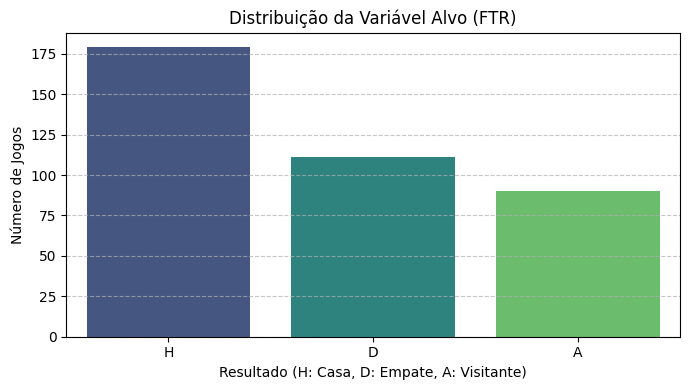



5. MATRIZ DE CORRELAÇÃO


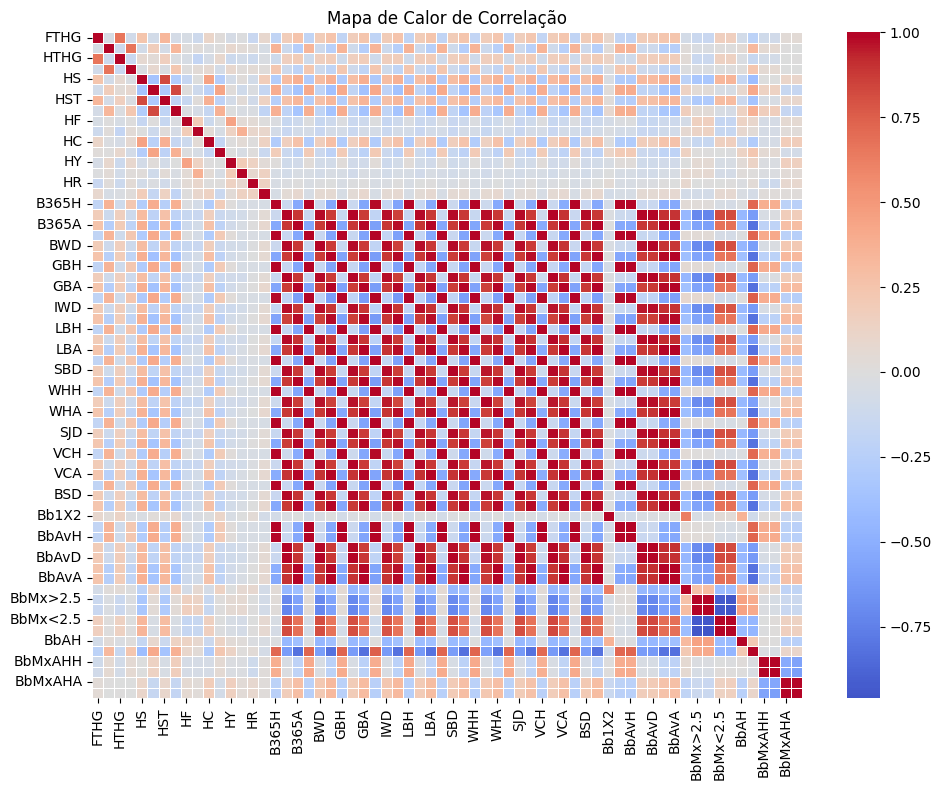

In [4]:
meus_datasets = analisar_pasta_datasets(caminho_pasta="/data", coluna_alvo="FTR")